# IE 7615 — Discriminative Project, Milestone 2 (Group 3)
## Multi-object detection with YOLOv8

Given an image containing several of the 73 class objects, the trained model reports the
**Object ID, name and location** of every object in it.

**What this notebook does**
1. Rebuilds the Milestone 1 photo split exactly (seed 42), so detection train / validation / test
   images are built only from Milestone 1 train / validation / test photos.
2. Uses one reviewed bounding box per photo (object-level, found once with the OWLv2 zero-shot
   detector, then audited and reviewed).
3. Generates multi-object images by concatenating photos: strict edge-to-edge grids, jittered
   grids and random collages, with background-only photos as negatives.
4. Fine-tunes COCO-pretrained YOLOv8s at 960 px input (to help with small objects), then evaluates it on held-out test images and on a
   stress suite of strict grids (1x2 to 3x3).

**Runtime:** about 95 minutes on a Colab T4 (training is fixed to ~80 minutes by a timing run).

| Section | Contents |
|---|---|
| 1 | Setup and configuration |
| 2 | Data and the Milestone 1 split |
| 3 | Object boxes |
| 4 | Generated images |
| 5 | Training (timing run, then YOLOv8s) |
| 6 | Test-set detection metrics |
| 7 | Image-level score (requirement 3) |
| 8 | Detector vs Milestone 1 classifier |
| 9 | Scene check on background photos |
| 10 | Failure gallery |
| 11 | Inference on any image |
| 12 | Save outputs |
| 13 | Summary of findings |

---
## 1. Setup and configuration

In [1]:
import os, sys, json, time, shutil, zipfile, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.4.162"], check=True)

import numpy as np
import torch
import ultralytics
from ultralytics import YOLO
print("ultralytics", ultralytics.__version__, "| torch", torch.__version__,
      "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
ultralytics 8.4.162 | torch 2.11.0+cu130 | GPU: Tesla T4


In [2]:
# ---------------------------------------------------------------- configuration
SMOKE_TEST         = False   # True: tiny sets, 1 epoch, small images -- checks the pipeline only
RETRAIN_ALL_PHOTOS = False   # off: no extra model trained on all photos

MODEL         = "yolov8s.pt" # COCO-pretrained weights (transfer learning)
IMGSZ         = 960
BATCH         = 16
SEED          = 42
PATIENCE      = 15           # early stopping on validation fitness
TRAIN_MINUTES = 80           # budget used by the timing run to fix the epoch count
AUG = dict(mosaic=0.0,       # images are already composites; mosaic would shrink objects again
           close_mosaic=0,
           scale=0.2,        # +-20% zoom: generation already varies scale and keeps objects >= 24 px
           fliplr=0.5,       # mirroring is fine for classification (Milestone 1 also used it)
           degrees=0.0, translate=0.1)

# ---------------------------------------------------------------- paths
# The class dataset zip and the support zip live in your own Drive (MyDrive).
# Nothing is ever written to the shared class folder; all work happens on local
# Colab disk and the only Drive write is the outputs zip at OUTPUT_ZIP.
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    MYDRIVE     = Path("/content/drive/MyDrive")
    DATASET_ZIP = MYDRIVE / "IE7615 Deep Learning for AI-20261003T002312Z-1-001.zip"
    SUPPORT_ZIP = MYDRIVE / "m2_support.zip"
    WORK        = Path("/content/m2")
    OUTPUT_ZIP  = MYDRIVE / "IE7615_Milestone2_outputs_960.zip"
else:
    DATASET_ZIP = Path(os.environ["M2_DATASET_ZIP"])
    SUPPORT_ZIP = Path(os.environ["M2_SUPPORT_ZIP"])
    WORK        = Path(os.environ["M2_WORK"])
    OUTPUT_ZIP  = WORK / "IE7615_Milestone2_outputs_960.zip"
DEVICE = 0 if torch.cuda.is_available() else "cpu"


def assert_safe_write(path):
    # Allow writes on local disk and to the single outputs zip; refuse anything else in Drive.
    p = Path(path).resolve()
    if str(p).startswith("/content/drive") and p != OUTPUT_ZIP.resolve():
        raise RuntimeError(f"refusing to write inside Google Drive: {p}")
    return p


for d in ("src", "data", "boxes", "review", "datasets", "runs", "outputs"):
    assert_safe_write(WORK / d).mkdir(parents=True, exist_ok=True)
os.environ.update(M2_ROOT=str(WORK), M2_DATA=str(WORK / "data" / "IE7615 Deep Learning for AI"),
                  M2_NAMES=str(WORK / "boxes" / "object_names.csv"))
os.chdir(WORK)
sys.path.insert(0, str(WORK / "src"))
OUT = WORK / "outputs"
if SMOKE_TEST:
    IMGSZ, BATCH = 320, 8
print("work dir:", WORK, "| outputs zip:", OUTPUT_ZIP)

Mounted at /content/drive
work dir: /content/m2 | outputs zip: /content/drive/MyDrive/IE7615_Milestone2_outputs_960.zip


---
## 2. Data and the Milestone 1 split

The dataset zip is extracted to local disk. The support zip holds the inputs prepared before
training: the OWLv2 box candidates for every photo, the review decisions, the final Object ID
sheet, and the Milestone 1 DenseNet121 predictions on its test photos.

The modules below are written to `src/` and imported, so the exact tested code is visible here.

In [3]:
t0 = time.time()
if not (WORK / "data" / "IE7615 Deep Learning for AI").exists():
    with zipfile.ZipFile(DATASET_ZIP) as z:
        z.extractall(WORK / "data")
with zipfile.ZipFile(SUPPORT_ZIP) as z:
    z.extractall(WORK)
print(f"extracted in {time.time() - t0:.0f}s")
print(sorted(p.name for p in (WORK / "boxes").iterdir()), sorted(p.name for p in (WORK / "review").iterdir()))

extracted in 9s
['m1_densenet121_test_predictions.csv', 'object_names.csv', 'owlv2_candidates.jsonl'] ['audit_judgments.csv', 'valtest_decisions.csv']


In [4]:
%%writefile src/m2data.py
"""Dataset manifest, deduplication and the Milestone 1 train/val/test split.

Pure Python + PIL. Reproduces Milestone 1 exactly:
  * background photos are files matching `_bg_?<digit>` (case-insensitive)
  * exact duplicates are removed before splitting; when copies carry different
    labels the object copy is kept (object files are visited before backgrounds)
  * per-class stratified 70/15/15 split with one `random.Random(42)` shared
    across classes in sorted class order
On this dataset every duplicate Milestone 1 removed was byte-identical, so an
MD5 key gives the same groups as Milestone 1's perceptual signature.
"""
import csv
import hashlib
import os
import random
import re
from collections import defaultdict
from pathlib import Path

from PIL import Image, ImageOps

EXTS = {".jpg", ".jpeg", ".png"}
BG_RE = re.compile(r"_bg_?\d", re.IGNORECASE)
SEED = 42
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15

# Project layout; each path can be overridden with an environment variable.
ROOT = Path(os.environ.get("M2_ROOT", Path(__file__).resolve().parents[1]))
DATA_DIR = Path(os.environ.get("M2_DATA", ROOT / "data" / "IE7615 Deep Learning for AI"))
NAMES_CSV = Path(os.environ.get("M2_NAMES", ROOT / "boxes" / "object_names.csv"))


class Photo:
    __slots__ = ("path", "label", "obj", "idx", "is_bg", "md5", "split")

    def __init__(self, path, label, obj, idx, is_bg):
        self.path, self.label, self.obj, self.idx, self.is_bg = path, label, obj, idx, is_bg
        self.md5 = self.split = None

    @property
    def rel(self):
        return f"{self.path.parent.name}/{self.path.name}"


def load_names(csv_path):
    """Object ID -> name from the final Object ID sheet export."""
    with open(csv_path, newline="") as fh:
        return {r["object_id"]: r["object_name"].strip() for r in csv.DictReader(fh)
                if r["object_id"].startswith("OBJ")}


def scan(data_dir):
    """All image files in images_OBJxxx folders, in Milestone 1's order."""
    photos = []
    for d in sorted(p for p in Path(data_dir).iterdir() if p.is_dir() and p.name.startswith("images_")):
        obj = d.name.replace("images_", "")
        for f in sorted(d.iterdir()):
            if not f.is_file() or f.suffix.lower() not in EXTS:
                continue
            is_bg = bool(BG_RE.search(f.name))
            nums = re.findall(r"\d+", f.stem)
            idx = int(nums[1]) if len(nums) > 1 else -1
            photos.append(Photo(f, "background" if is_bg else obj, obj, idx, is_bg))
    return photos


def dedupe(photos):
    """Drop exact duplicates; returns (kept in original order, dropped)."""
    seen, keep, dropped = {}, set(), []
    for p in sorted(photos, key=lambda p: p.is_bg):          # stable: object files first
        p.md5 = hashlib.md5(p.path.read_bytes()).hexdigest()
        if p.md5 in seen:
            dropped.append((p, seen[p.md5]))
        else:
            seen[p.md5] = p
            keep.add(id(p))
    return [p for p in photos if id(p) in keep], dropped


def split(photos):
    """Assign p.split in {'train','val','test'} exactly as Milestone 1 did."""
    by_class = defaultdict(list)
    for p in photos:
        by_class[p.label].append(p)
    rng = random.Random(SEED)
    for label, rows in sorted(by_class.items()):
        rows = sorted(rows, key=lambda p: (p.obj, p.idx))
        rows = rows[:]
        rng.shuffle(rows)
        n = len(rows)
        n_tr, n_va = int(n * TRAIN_FRAC), int(n * VAL_FRAC)
        for i, p in enumerate(rows):
            p.split = "train" if i < n_tr else "val" if i < n_tr + n_va else "test"
    return photos


def build(data_dir):
    """Scan, deduplicate and split. Returns (photos, dropped)."""
    photos, dropped = dedupe(scan(data_dir))
    return split(photos), dropped


def open_upright(path):
    """RGB image with EXIF orientation applied (phone photos store rotation as a tag)."""
    with Image.open(path) as im:
        return ImageOps.exif_transpose(im).convert("RGB")

Writing src/m2data.py


In [5]:
%%writefile src/draw.py
"""Draw YOLO labels back onto generated images (reads the label files, not the manifest)."""
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont

FONT_PATHS = ["/System/Library/Fonts/Supplemental/Arial Bold.ttf", "/System/Library/Fonts/Helvetica.ttc",
              "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf"]


def font(size):
    for f in FONT_PATHS:
        if Path(f).exists():
            return ImageFont.truetype(f, size)
    return ImageFont.load_default(size)


def draw_labels(img_path, label_path, ids, names, size=14):
    im = Image.open(img_path).convert("RGB"); W, H = im.size
    d = ImageDraw.Draw(im); f = font(size)
    for line in Path(label_path).read_text().splitlines():
        c, cx, cy, w, h = line.split(); c = int(c)
        cx, cy, w, h = float(cx) * W, float(cy) * H, float(w) * W, float(h) * H
        x0, y0, x1, y1 = cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2
        d.rectangle([x0, y0, x1, y1], outline=(255, 40, 40), width=3)
        txt = f"{ids[c]} {names[ids[c]]}"
        tw = d.textlength(txt, font=f)
        d.rectangle([x0, max(0, y0 - size - 4), x0 + tw + 4, max(size + 4, y0)], fill=(255, 40, 40))
        d.text((x0 + 2, max(0, y0 - size - 3)), txt, fill="white", font=f)
    return im

Writing src/draw.py


In [6]:
%%writefile src/select_boxes.py
"""Choose one box per object photo from the OWLv2 candidates, flag doubtful ones,
and build the review sheets.

The label box is always the top-scoring candidate: each photo shows exactly one
known object. A photo is flagged for review when
  low        its top score is below LOW_SCORE
  rival      a separate candidate (IoU with the top box < 0.3) scores at least
             RIVAL_RATIO x the top score: a second copy or a look-alike distractor
             (a stricter ratio applies to classes with look-alikes in the dataset)
  huge       the box covers at least 90% of the frame
How flagged photos are resolved, based on a 146-photo random audit (1/114
unflagged boxes wrong, 0/7 low-score-only, 6/20 rival-only, 4/4 rival + low):
  * classes whose rival is usually another part of the same object (a pair of
    sneakers, a tissue and its box, the halves of an open wallet,
    the head and body of a figure) use the union of the two boxes when they
    touch or nearly touch
  * validation and test photos with a rival were reviewed one by one
    (review/valtest_decisions.csv: A top box, B rival, U union, X exclude)
  * training photos with rival + low score are excluded, and so are training
    photos with a rival in classes where the top box was wrong in at least half
    of that class's reviewed val/test rival photos (at least 3 reviewed); the
    remaining training photos keep the top box (~2% estimated label noise)

Outputs: boxes/boxes.csv, boxes/flag_counts.csv, review/*.jpg sheets.
Usage:  python src/select_boxes.py [counts|sheets]
"""
import csv
import json
import random
import sys
from collections import Counter
from pathlib import Path

from PIL import Image, ImageDraw

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT / "src"))
import draw    # noqa: E402
import m2data  # noqa: E402

ROOT = m2data.ROOT
DATA = m2data.DATA_DIR
NAMES = m2data.load_names(m2data.NAMES_CSV)
CAND = ROOT / "boxes" / "owlv2_candidates.jsonl"
REJECTED = ROOT / "boxes" / "rejected.txt"
LOW_SCORE = 0.10
RIVAL_RATIO = 0.5
LOOKALIKE_RATIO = 0.3
LOOKALIKES = {"OBJ025", "OBJ046", "OBJ065", "OBJ061", "OBJ067", "OBJ014", "OBJ045", "OBJ048", "OBJ057"}
CELL = 200
UNION_CLASSES = {"OBJ010", "OBJ051", "OBJ067", "OBJ070"}
DECISIONS = ROOT / "review" / "valtest_decisions.csv"


def near(a, b, tol=0.15):
    """Boxes overlap, or the gap between them is under tol x the larger box's size."""
    g = tol * max(a[2] - a[0], a[3] - a[1], b[2] - b[0], b[3] - b[1])
    return not (a[2] + g < b[0] or b[2] + g < a[0] or a[3] + g < b[1] or b[3] + g < a[1])


def union(a, b):
    return [min(a[0], b[0]), min(a[1], b[1]), max(a[2], b[2]), max(a[3], b[3])]


def load():
    rows = [json.loads(l) for l in CAND.read_text().splitlines() if l.strip()]
    decisions, unreliable = {}, set()
    if DECISIONS.exists():
        with open(DECISIONS, newline="") as fh:
            dec_rows = list(csv.DictReader(fh))
        decisions = {d["rel"]: d["decision"] for d in dec_rows}
        for oid in {d["object_id"] for d in dec_rows} - UNION_CLASSES:
            ds = [d["decision"] for d in dec_rows if d["object_id"] == oid]
            if len(ds) >= 3 and sum(x in ("B", "X") for x in ds) / len(ds) >= 0.5:
                unreliable.add(oid)
    for r in rows:
        top = r["candidates"][0]
        x0, y0, x1, y1 = top["box"]
        r["score"] = top["score"]
        r["area"] = (x1 - x0) * (y1 - y0) / (r["w"] * r["h"])
        ratio = LOOKALIKE_RATIO if r["object_id"] in LOOKALIKES else RIVAL_RATIO
        rivals = [c for c in r["candidates"][1:] if c["iou_top1"] < 0.3 and c["score"] >= ratio * top["score"]]
        r["rival"] = rivals[0] if rivals else None
        r["flags"] = [f for f, on in (("low", top["score"] < LOW_SCORE), ("rival", bool(rivals)),
                                      ("huge", r["area"] >= 0.9)) if on]
        r["badness"] = (top["score"] < LOW_SCORE) * (1 - top["score"]) + \
                       (rivals[0]["score"] / max(top["score"], 1e-6) if rivals else 0) + (r["area"] >= 0.9)
        r["box"], r["source"], r["exclude"] = top["box"], "top", ""
        rival_box = r["rival"]["box"] if r["rival"] else None
        if rival_box and r["object_id"] in UNION_CLASSES and near(top["box"], rival_box):
            r["box"], r["source"] = union(top["box"], rival_box), "union"
        d = decisions.get(r["rel"])
        if r["split"] in ("val", "test") and d:
            if d == "X":
                r["exclude"] = "reviewed: no correct box"
            elif d == "B":
                r["box"], r["source"] = rival_box, "reviewed: rival"
            elif d == "U":
                r["box"], r["source"] = union(top["box"], rival_box), "reviewed: union"
            else:
                r["box"], r["source"] = top["box"], "reviewed: top"
        elif r["split"] == "train" and "rival" in r["flags"] and r["source"] != "union":
            if "low" in r["flags"]:
                r["exclude"] = "train: rival + low score (4/4 wrong in audit)"
            elif r["object_id"] in unreliable:
                r["exclude"] = "train: rival in a class whose reviewed rival boxes were mostly wrong"
    return rows


def write_boxes(rows):
    with open(ROOT / "boxes" / "boxes.csv", "w", newline="") as fh:
        w = csv.writer(fh)
        w.writerow(["rel", "object_id", "split", "x0", "y0", "x1", "y1", "img_w", "img_h",
                    "score", "prompt", "flags", "source"])
        for r in sorted(rows, key=lambda r: r["rel"]):
            if not r["exclude"]:
                w.writerow([r["rel"], r["object_id"], r["split"], *[round(v, 1) for v in r["box"]], r["w"], r["h"],
                            r["score"], r["candidates"][0]["prompt"], "|".join(r["flags"]), r["source"]])
    with open(ROOT / "boxes" / "excluded.csv", "w", newline="") as fh:
        w = csv.writer(fh); w.writerow(["rel", "object_id", "split", "reason"])
        for r in sorted(rows, key=lambda r: r["rel"]):
            if r["exclude"]:
                w.writerow([r["rel"], r["object_id"], r["split"], r["exclude"]])


def counts(rows):
    by_cls = Counter(r["object_id"] for r in rows if r["flags"])
    kinds = Counter(f for r in rows for f in r["flags"])
    with open(ROOT / "boxes" / "flag_counts.csv", "w", newline="") as fh:
        w = csv.writer(fh)
        w.writerow(["object_id", "object_name", "photos", "flagged", "low", "rival", "huge", "union", "excluded"])
        for oid in sorted(NAMES):
            rs = [r for r in rows if r["object_id"] == oid]
            w.writerow([oid, NAMES[oid], len(rs), sum(bool(r["flags"]) for r in rs),
                        *(sum(f in r["flags"] for r in rs) for f in ("low", "rival", "huge")),
                        sum(r["source"].endswith("union") for r in rs), sum(bool(r["exclude"]) for r in rs)])
    return by_cls, kinds


def cell(r, show_rival=True, tag=""):
    im = m2data.open_upright(DATA / r["rel"])
    k = CELL / max(im.size)
    im = im.resize((round(im.width * k), round(im.height * k)))
    canvas = Image.new("RGB", (CELL, CELL + 30), "white"); canvas.paste(im, (0, 30))
    d = ImageDraw.Draw(canvas)
    if show_rival and r["rival"]:
        x0, y0, x1, y1 = (v * k for v in r["rival"]["box"])
        d.rectangle([x0, y0 + 30, x1, y1 + 30], outline=(255, 220, 0), width=2)
    x0, y0, x1, y1 = (v * k for v in r["box"])
    d.rectangle([x0, y0 + 30, x1, y1 + 30], outline=(255, 30, 30), width=3)
    f = draw.font(11)
    d.text((2, 1), f"{tag}{r['object_id']} {NAMES[r['object_id']][:20]}", fill="black", font=f)
    d.text((2, 15), f"s={r['score']:.2f} a={r['area']:.0%} {','.join(r['flags'])}"[:34], fill=(150, 0, 0), font=f)
    return canvas


def sheet(rows, path, cols=10, **kw):
    n = len(rows); nr = (n + cols - 1) // cols
    S = Image.new("RGB", (cols * CELL, nr * (CELL + 30)), "white")
    for i, r in enumerate(rows):
        S.paste(cell(r, **kw), ((i % cols) * CELL, (i // cols) * (CELL + 30)))
    S.save(path, quality=85)


def sheets(rows, max_flagged=300, per_page=60):
    flagged = sorted((r for r in rows if r["flags"]), key=lambda r: -r["badness"])[:max_flagged]
    for p in range(0, len(flagged), per_page):
        sheet(flagged[p:p + per_page], ROOT / "review" / f"flagged_{p // per_page + 1:02d}.jpg")
    rng = random.Random(2026)
    audit = []
    for oid in sorted(NAMES):
        audit += rng.sample([r for r in rows if r["object_id"] == oid], 2)
    for p in range(0, len(audit), per_page):
        sheet(audit[p:p + per_page], ROOT / "review" / f"audit_{p // per_page + 1:02d}.jpg", show_rival=False)
    with open(ROOT / "review" / "audit_list.csv", "w", newline="") as fh:
        w = csv.writer(fh); w.writerow(["sheet_position", "rel", "object_id", "score", "flags"])
        for i, r in enumerate(audit, 1):
            w.writerow([i, r["rel"], r["object_id"], r["score"], "|".join(r["flags"])])
    return len(flagged), len(audit)


if __name__ == "__main__":
    rows = load()
    write_boxes(rows)
    by_cls, kinds = counts(rows)
    print(f"{len(rows)} photos; flagged {sum(bool(r['flags']) for r in rows)}; by kind {dict(kinds)}")
    print("flagged per class (top 15):", by_cls.most_common(15))
    if "sheets" in sys.argv:
        print("sheets: flagged %d, audit %d" % sheets(rows))

Writing src/select_boxes.py


In [7]:
%%writefile src/m2compose.py
"""Compose multi-object detection images from single-object photos.

Three layouts, each with a reason:
  grid     (50%)  photos touching edge to edge in a strict rows x cols grid, the
                  simplest way to "concatenate" photos and the likeliest test format
  jitter   (20%)  a grid with gaps, random offsets and per-photo scale, so the
                  detector cannot rely on objects sitting exactly on a grid
  collage  (30%)  photos at random positions and scales, no overlap
Grids use native 224 px photos 70% of the time and a uniformly smaller size
(112-224 px) otherwise. Jitter and collage canvases are a mosaic of same-split
background photos at native resolution, so a pasted photo is never a sharper
patch on a blurry, upscaled background.

Any slot can hold a background-only photo (no label), about 10% of images
repeat a class with a different photo, and about 2% hold only backgrounds.
Each photo is flipped horizontally with probability 0.5 and its brightness is
scaled by 0.85-1.15; its object box is transformed with it.

Everything is driven by one random.Random(seed), so a seed reproduces the set,
and every image's manifest entry lists each placed photo, its region and box.
"""
import random
from pathlib import Path

from PIL import Image, ImageEnhance

import m2data

TILE = 224
GRID_LAYOUTS = [(1, 2), (2, 1), (1, 3), (3, 1), (1, 4), (4, 1),
                (2, 2), (2, 3), (3, 2), (3, 3), (2, 4), (4, 2)]
MIX = {"grid": 0.50, "jitter": 0.20, "collage": 0.30}
P_BG_SLOT = 0.12
P_REPEAT = 0.10
P_ALL_BG = 0.02
MIN_OBJ_PX = 24
ASPECTS = [(1, 1), (4, 3), (3, 4), (2, 1), (1, 2), (16, 9)]


class Pool:
    """Supplies object photos for one split.

    single_pass=True (val/test): one shuffled pass, every photo used exactly once.
    single_pass=False (train): class-balanced -- classes are taken round-robin
    in shuffled order and each class cycles through its own shuffled photos, so
    every class appears about equally often however many photos it has.
    """

    def __init__(self, photos, rng, single_pass=False):
        self.photos, self.rng, self.single_pass = list(photos), rng, single_pass
        self.order, self.used, self.passes = [], set(), 0
        self._refill()
        if not single_pass:
            self.by_class = {}
            for p in self.photos:
                self.by_class.setdefault(p.label, []).append(p)
            self.queues = {k: [] for k in self.by_class}
            self.class_cycle = []

    def _next_of_class(self, label):
        q = self.queues[label]
        if not q:
            q.extend(self.by_class[label]); self.rng.shuffle(q)
        return q.pop()

    def _balanced_next(self, exclude_labels):
        for _ in range(2 * len(self.by_class)):
            if not self.class_cycle:
                self.class_cycle = sorted(self.by_class); self.rng.shuffle(self.class_cycle)
            label = self.class_cycle.pop()
            if label not in exclude_labels:
                return self._next_of_class(label)
        return self._next_of_class(self.rng.choice(sorted(self.by_class)))

    def _refill(self):
        self.order = self.photos[:]
        self.rng.shuffle(self.order)
        self.used, self.pos = set(), 0
        self.passes += 1

    def exhausted(self):
        return self.single_pass and len(self.used) == len(self.photos)

    def next(self, exclude_labels=()):
        if not self.single_pass:
            return self._balanced_next(exclude_labels)
        for _ in range(2):
            while self.pos < len(self.order):
                p = self.order[self.pos]; self.pos += 1
                if id(p) not in self.used and p.label not in exclude_labels:
                    self.used.add(id(p)); return p
            # only labels in exclude_labels remain: take any unused photo instead
            for p in self.order:
                if id(p) not in self.used:
                    self.used.add(id(p)); return p
            if self.single_pass:
                return None
            self._refill()
        return None

    def release(self, p):
        """Return an unused-after-all photo to a single-pass pool."""
        self.used.discard(id(p)); self.pos = 0

    def same_class(self, label, not_this):
        """A photo of `label` other than `not_this` (for repeats); unused in a single pass."""
        if not self.single_pass:
            cands = [p for p in self.by_class.get(label, []) if p is not not_this]
            return self.rng.choice(cands) if cands else None
        for p in self.order[self.pos:] + self.order[:self.pos]:
            if p.label == label and p is not not_this and id(p) not in self.used:
                self.used.add(id(p)); return p
        if self.single_pass:
            return None
        cands = [p for p in self.by_class.get(label, []) if p is not not_this]
        return self.rng.choice(cands) if cands else None


class Composer:
    def __init__(self, photos, boxes, split, seed, single_pass=False):
        self.rng = random.Random(seed)
        in_split = [p for p in photos if split is None or p.split == split]   # None: all photos
        objs = [p for p in in_split if not p.is_bg and p.rel in boxes]
        self.bgs = sorted((p for p in in_split if p.is_bg), key=lambda p: p.rel)
        self.pool = Pool(sorted(objs, key=lambda p: p.rel), self.rng, single_pass)
        self.boxes = boxes
        self._cache = {}

    # ------------------------------------------------------------------ tiles
    def tile(self, p):
        """Square 224 px upright photo (centre-cropped if not square) and its box."""
        if p.rel not in self._cache:
            im = m2data.open_upright(p.path)
            w, h = im.size
            s = min(w, h); ox, oy = (w - s) // 2, (h - s) // 2
            im = im.crop((ox, oy, ox + s, oy + s))
            k = TILE / s
            if im.size != (TILE, TILE):
                im = im.resize((TILE, TILE), Image.BICUBIC)
            box = None
            if not p.is_bg:
                x0, y0, x1, y1 = self.boxes[p.rel]
                box = [min(max((x0 - ox) * k, 0), TILE), min(max((y0 - oy) * k, 0), TILE),
                       min(max((x1 - ox) * k, 0), TILE), min(max((y1 - oy) * k, 0), TILE)]
            self._cache[p.rel] = (im, box)
        return self._cache[p.rel]

    def render(self, p, size):
        """Photo p at size x size px with flip/brightness; returns (image, box, flipped)."""
        im, box = self.tile(p)
        flip = self.rng.random() < 0.5
        bright = self.rng.uniform(0.85, 1.15)
        if size != TILE:
            im = im.resize((size, size), Image.BICUBIC)
        if flip:
            im = im.transpose(Image.FLIP_LEFT_RIGHT)
        im = ImageEnhance.Brightness(im).enhance(bright)
        if box is not None:
            k = size / TILE
            x0, y0, x1, y1 = (v * k for v in box)
            box = [size - x1, y0, size - x0, y1] if flip else [x0, y0, x1, y1]
        return im, box, flip

    def min_size(self, p):
        """Smallest paste size that keeps the object's shorter side >= MIN_OBJ_PX."""
        _, box = self.tile(p)
        short = min(box[2] - box[0], box[3] - box[1])
        return int(min(TILE * 1.25, max(TILE * 0.5, MIN_OBJ_PX * TILE / max(short, 1))))

    # ------------------------------------------------------------- canvases
    def bg_canvas(self, W, H):
        canvas = Image.new("RGB", (W, H))
        ox, oy = -self.rng.randrange(TILE), -self.rng.randrange(TILE)
        pieces = []
        for y in range(oy, H, TILE):
            for x in range(ox, W, TILE):
                b = self.rng.choice(self.bgs)
                im, _ = self.tile(b)
                if self.rng.random() < 0.5:
                    im = im.transpose(Image.FLIP_LEFT_RIGHT)
                canvas.paste(im, (x, y))
                pieces.append({"kind": "canvas", "rel": b.rel, "obj": b.obj,
                               "region": [max(x, 0), max(y, 0), min(x + TILE, W), min(y + TILE, H)]})
        return canvas, pieces

    # --------------------------------------------------------------- slots
    def slot_photos(self, n):
        """n photos for one image: objects (balanced), maybe background slots/repeats."""
        if self.rng.random() < P_ALL_BG:
            return [self.rng.choice(self.bgs) for _ in range(n)]
        kinds = ["bg" if self.rng.random() < P_BG_SLOT else "obj" for _ in range(n)]
        if "obj" not in kinds:
            kinds[self.rng.randrange(n)] = "obj"
        out, labels = [], set()
        for k in kinds:
            if k == "bg":
                out.append(self.rng.choice(self.bgs)); continue
            p = self.pool.next(exclude_labels=labels)
            if p is None:                          # single pass used up: fill with backgrounds
                out.append(self.rng.choice(self.bgs)); continue
            out.append(p); labels.add(p.label)
        objs = [i for i, p in enumerate(out) if not p.is_bg]
        if len(objs) >= 2 and self.rng.random() < P_REPEAT:
            src, dst = self.rng.sample(objs, 2)
            twin = self.pool.same_class(out[src].label, out[src])
            if twin is not None:
                if self.pool.single_pass:          # the replaced photo goes into a later image
                    self.pool.release(out[dst])
                out[dst] = twin
        self.rng.shuffle(out)
        return out

    # --------------------------------------------------------------- layouts
    def grid(self, layout=None, tile=None):
        rows, cols = layout or self.rng.choice(GRID_LAYOUTS)
        if tile is None:
            tile = TILE if self.rng.random() < 0.7 else self.rng.randint(TILE // 2, TILE)
        ps = self.slot_photos(rows * cols)
        canvas = Image.new("RGB", (cols * tile, rows * tile), (0, 0, 0))
        items = []
        for i, p in enumerate(ps):
            r, c = divmod(i, cols)
            im, box, flip = self.render(p, tile)
            x, y = c * tile, r * tile
            canvas.paste(im, (x, y))
            items.append(self._item(p, [x, y, x + tile, y + tile], box, x, y, flip))
        return canvas, items, {"layout": "grid", "rows": rows, "cols": cols, "tile": tile}

    def jitter(self):
        rows, cols = self.rng.choice(GRID_LAYOUTS)
        cell = int(TILE * self.rng.uniform(1.05, 1.35))
        W, H = cols * cell, rows * cell
        canvas, pieces = self.bg_canvas(W, H)
        items = []
        for i, p in enumerate(self.slot_photos(rows * cols)):
            r, c = divmod(i, cols)
            hi = min(cell, int(TILE * 1.25))
            lo = min(self.min_size(p) if not p.is_bg else int(TILE * 0.6), hi)
            size = self.rng.randint(lo, hi)
            x = c * cell + self.rng.randint(0, cell - size)
            y = r * cell + self.rng.randint(0, cell - size)
            im, box, flip = self.render(p, size)
            canvas.paste(im, (x, y))
            items.append(self._item(p, [x, y, x + size, y + size], box, x, y, flip))
        return canvas, items + self._visible(pieces, items), {"layout": "jitter", "rows": rows, "cols": cols}

    def collage(self):
        aw, ah = self.rng.choice(ASPECTS)
        long_side = self.rng.randint(448, 896)
        W, H = (long_side, int(long_side * ah / aw)) if aw >= ah else (int(long_side * aw / ah), long_side)
        canvas, pieces = self.bg_canvas(W, H)
        ps = self.slot_photos(self.rng.randint(2, 6))
        placed, items = [], []
        for p in ps:
            lo = self.min_size(p) if not p.is_bg else int(TILE * 0.6)
            for attempt in range(300):
                size = self.rng.randint(lo, max(lo, int(TILE * 1.25)))
                size = min(size, W, H)
                x, y = self.rng.randint(0, W - size), self.rng.randint(0, H - size)
                r = [x, y, x + size, y + size]
                if all(r[2] <= q[0] or q[2] <= r[0] or r[3] <= q[1] or q[3] <= r[1] for q in placed):
                    break
            else:
                continue                              # no room: leave this photo out
            im, box, flip = self.render(p, size)
            canvas.paste(im, (x, y))
            placed.append(r)
            items.append(self._item(p, r, box, x, y, flip))
        if self.pool.single_pass:
            for p in ps:                              # photos left out go back for a later image
                if not p.is_bg and not any(it["rel"] == p.rel for it in items):
                    self.pool.release(p)
        return canvas, items + self._visible(pieces, items), {"layout": "collage", "W": W, "H": H}

    # --------------------------------------------------------------- helpers
    @staticmethod
    def _item(p, region, box, x, y, flip):
        it = {"kind": "background" if p.is_bg else "object", "rel": p.rel, "obj": p.obj,
              "label": p.label, "region": region, "flipped": flip}
        if box is not None:
            it["box"] = [round(box[0] + x, 1), round(box[1] + y, 1), round(box[2] + x, 1), round(box[3] + y, 1)]
        return it

    @staticmethod
    def _visible(pieces, items):
        """Canvas pieces not fully covered by pasted photos (used by the scene check)."""
        out = []
        for c in pieces:
            r = c["region"]
            if r[2] - r[0] < 8 or r[3] - r[1] < 8:
                continue
            covered = any(i["region"][0] <= r[0] and i["region"][1] <= r[1] and
                          i["region"][2] >= r[2] and i["region"][3] >= r[3] for i in items)
            if not covered:
                out.append(c)
        return out

    def make(self, kind=None, **kw):
        kind = kind or self.rng.choices(list(MIX), weights=list(MIX.values()))[0]
        return getattr(self, kind)(**kw)


def yolo_lines(items, W, H, class_index):
    out = []
    for it in items:
        if it["kind"] != "object":
            continue
        x0, y0, x1, y1 = it["box"]
        out.append(f"{class_index[it['label']]} {(x0 + x1) / 2 / W:.6f} {(y0 + y1) / 2 / H:.6f} "
                   f"{(x1 - x0) / W:.6f} {(y1 - y0) / H:.6f}")
    return out


def write_set(composer, out_dir, n_images=None, kind=None, prefix="img", class_index=None, **kw):
    """Generate images + YOLO labels into out_dir/images and out_dir/labels.

    n_images=None means: keep going until the (single-pass) pool is used up.
    Returns the manifest (one dict per image).
    """
    out_dir = Path(out_dir)
    (out_dir / "images").mkdir(parents=True, exist_ok=True)
    (out_dir / "labels").mkdir(parents=True, exist_ok=True)
    manifest, i = [], 0
    while (n_images is None and not composer.pool.exhausted()) or (n_images is not None and i < n_images):
        canvas, items, meta = composer.make(kind, **kw)
        if not any(it["kind"] == "object" for it in items) and n_images is None and composer.pool.exhausted():
            break
        name = f"{prefix}_{i:05d}"
        W, H = canvas.size
        canvas.save(out_dir / "images" / f"{name}.jpg", quality=95)
        (out_dir / "labels" / f"{name}.txt").write_text("\n".join(yolo_lines(items, W, H, class_index)))
        manifest.append({"image": f"{name}.jpg", "W": W, "H": H, **meta, "items": items})
        i += 1
    return manifest

Writing src/m2compose.py


In [8]:
%%writefile src/build_datasets.py
"""Build every generated image set from the photos and boxes/boxes.csv.

  train   3,000 images from Milestone 1 training photos (balanced passes)
  val     validation photos, each object photo used exactly once
  test    test photos, each object photo used exactly once
  stress  strict grids at 224 px from test photos only:
          40 images each of 1x2, 1x4, 2x2, 2x3 and 3x3
  members four record sets of 100 images (one per group member), from all photos

Writes YOLO images/labels, data.yaml, classes.csv and one manifest JSON per set.
Usage:  python src/build_datasets.py OUT_DIR [--small]
"""
import csv
import json
import sys
import time
from collections import Counter
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT / "src"))
import m2compose  # noqa: E402
import m2data     # noqa: E402

ROOT = m2data.ROOT
DATA = m2data.DATA_DIR
NAMES_CSV = m2data.NAMES_CSV
SEEDS = {"train": 1, "val": 2, "test": 3, "stress": 4}
MEMBER_SEEDS = {"member1": 101, "member2": 102, "member3": 103, "member4": 104}
STRESS_LAYOUTS = [(1, 2), (1, 4), (2, 2), (2, 3), (3, 3)]
N_TRAIN, N_STRESS_EACH, N_MEMBER = 3000, 40, 100


def load_boxes(path):
    with open(path, newline="") as fh:
        return {r["rel"]: [float(r[k]) for k in ("x0", "y0", "x1", "y1")] for r in csv.DictReader(fh)}


def main(out, small=False):
    out = Path(out); out.mkdir(parents=True, exist_ok=True)
    names = m2data.load_names(NAMES_CSV)
    ids = sorted(names)
    assert ids == [f"OBJ{i:03d}" for i in range(1, 74)], "Object IDs are not OBJ001-OBJ073"
    cidx = {o: i for i, o in enumerate(ids)}
    photos, _ = m2data.build(DATA)
    boxes = load_boxes(ROOT / "boxes" / "boxes.csv")
    excluded = [p for p in photos if not p.is_bg and p.rel not in boxes]
    print(f"{len(boxes)} object photos with a box; {len(excluded)} excluded (see boxes/excluded.csv)")

    n_train = 60 if small else N_TRAIN
    n_stress = 4 if small else N_STRESS_EACH
    n_member = 10 if small else N_MEMBER
    summary = {}
    t0 = time.time()

    def save(name, manifest):
        (out / f"manifest_{name}.json").write_text(json.dumps(manifest))
        objs = [it for m in manifest for it in m["items"] if it["kind"] == "object"]
        summary[name] = {"images": len(manifest), "objects": len(objs),
                         "classes": len({it["label"] for it in objs}),
                         "layouts": dict(Counter(m["layout"] for m in manifest)),
                         "background_slots": sum(it["kind"] == "background" for m in manifest for it in m["items"]),
                         "images_with_repeat": sum(len({i["label"] for i in m["items"] if i["kind"] == "object"})
                                                   < sum(i["kind"] == "object" for i in m["items"]) for m in manifest)}
        print(f"{name:<8} {summary[name]}  ({time.time() - t0:.0f}s)", flush=True)

    comp = m2compose.Composer(photos, boxes, "train", SEEDS["train"])
    save("train", m2compose.write_set(comp, out / "train", n_images=n_train, prefix="train", class_index=cidx))

    for split in ("val", "test"):
        comp = m2compose.Composer(photos, boxes, split, SEEDS[split], single_pass=not small)
        man = m2compose.write_set(comp, out / split, n_images=(12 if small else None), prefix=split, class_index=cidx)
        if not small:
            used = Counter(it["rel"] for m in man for it in m["items"] if it["kind"] == "object")
            expect = {p.rel for p in photos if p.split == split and not p.is_bg and p.rel in boxes}
            assert set(used) == expect, f"{split}: {len(expect - set(used))} photos unused"
            extra = sum(c - 1 for c in used.values())
            print(f"{split}: every photo used; {extra} extra uses from repeated-class slots", flush=True)
        save(split, man)

    comp = m2compose.Composer(photos, boxes, "test", SEEDS["stress"])
    man = []
    for rows, cols in STRESS_LAYOUTS:
        part = m2compose.write_set(comp, out / "stress", n_images=n_stress, kind="grid",
                                   prefix=f"stress_{rows}x{cols}", class_index=cidx,
                                   layout=(rows, cols), tile=m2compose.TILE)
        man += part
    save("stress", man)

    for member, seed in MEMBER_SEEDS.items():
        comp = m2compose.Composer(photos, boxes, None, seed)
        save(member, m2compose.write_set(comp, out / "members" / member, n_images=n_member,
                                         prefix=f"{member}", class_index=cidx))

    with open(out / "classes.csv", "w", newline="") as fh:
        w = csv.writer(fh); w.writerow(["class_index", "object_id", "object_name"])
        for i, o in enumerate(ids):
            w.writerow([i, o, names[o]])
    yaml = [f"path: {out.resolve()}", "train: train/images", "val: val/images", "test: test/images", f"nc: {len(ids)}", "names:"]
    yaml += [f"  {i}: \"{o} {names[o]}\"" for i, o in enumerate(ids)]
    (out / "data.yaml").write_text("\n".join(yaml) + "\n")
    (out / "summary.json").write_text(json.dumps(summary, indent=1))


if __name__ == "__main__":
    main(sys.argv[1], small="--small" in sys.argv)

Writing src/build_datasets.py


In [9]:
%%writefile src/m2eval.py
"""Evaluation helpers for the generated detection sets.

Detections are dicts {"cls": int, "conf": float, "box": [x0, y0, x1, y1]} in
image pixels. Ground truth comes from the set's manifest (object items).

  match_image      greedy one-to-one matching (highest confidence first)
  image_correct    every object found with the right ID at IoU >= 0.5 and no
                   extra detections: the image-level score for requirement 3
  choose_threshold confidence threshold that maximises the image-level score
  per_photo        per pasted photo: was it detected with the right ID?
  scene_check      detections inside background-only regions, per background photo
"""
from collections import defaultdict

import numpy as np

IOU_MATCH = 0.5


def iou(a, b):
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def gt_objects(entry, class_index):
    return [{"cls": class_index[it["label"]], "box": it["box"], "rel": it["rel"]}
            for it in entry["items"] if it["kind"] == "object"]


def match_image(dets, gts, conf):
    """Returns (matched pairs [(det, gt)], unmatched dets, unmatched gts); class-aware."""
    dets = sorted((d for d in dets if d["conf"] >= conf), key=lambda d: -d["conf"])
    free = list(range(len(gts)))
    pairs, extra = [], []
    for d in dets:
        best, best_iou = None, IOU_MATCH
        for j in free:
            if gts[j]["cls"] == d["cls"]:
                v = iou(d["box"], gts[j]["box"])
                if v >= best_iou:
                    best, best_iou = j, v
        if best is None:
            extra.append(d)
        else:
            pairs.append((d, gts[best])); free.remove(best)
    return pairs, extra, [gts[j] for j in free]


def image_correct(dets, gts, conf):
    _, extra, missed = match_image(dets, gts, conf)
    return not extra and not missed


def image_accuracy(preds, manifest, class_index, conf, key=None):
    """Share of images that are fully correct; optionally grouped by key(entry)."""
    groups = defaultdict(list)
    for e in manifest:
        ok = image_correct(preds[e["image"]], gt_objects(e, class_index), conf)
        groups["all"].append(ok)
        if key:
            groups[key(e)].append(ok)
    return {k: (float(np.mean(v)), len(v)) for k, v in groups.items()}


def choose_threshold(preds, manifest, class_index, grid=None):
    grid = np.round(np.arange(0.05, 0.951, 0.05), 2) if grid is None else grid
    scores = [(float(t), image_accuracy(preds, manifest, class_index, t)["all"][0]) for t in grid]
    best = max(scores, key=lambda s: (s[1], -abs(s[0] - 0.5)))
    return best[0], scores


def per_photo(preds, manifest, class_index, conf):
    """For every pasted object photo: predicted class of the best detection
    overlapping its box (IoU >= 0.5, any class), or None if nothing was found."""
    out = []
    for e in manifest:
        dets = [d for d in preds[e["image"]] if d["conf"] >= conf]
        for g in gt_objects(e, class_index):
            cands = [d for d in dets if iou(d["box"], g["box"]) >= IOU_MATCH]
            best = max(cands, key=lambda d: d["conf"]) if cands else None
            out.append({"rel": g["rel"], "true": g["cls"], "pred": best["cls"] if best else None,
                        "image": e["image"]})
    return out


def scene_check(preds, manifest, class_index, conf):
    """Detections whose centre lies in a background-only region (a background
    tile or a visible canvas piece) and not inside any pasted object photo."""
    per_bg = defaultdict(lambda: {"shown": 0, "false_dets": 0, "own_object": 0, "obj": None})
    events = []
    for e in manifest:
        obj_regions = [it["region"] for it in e["items"] if it["kind"] == "object"]
        bg_items = [it for it in e["items"] if it["kind"] in ("background", "canvas")]
        for it in bg_items:
            per_bg[it["rel"]]["shown"] += 1
            per_bg[it["rel"]]["obj"] = it["obj"]
        for d in preds[e["image"]]:
            if d["conf"] < conf:
                continue
            cx, cy = (d["box"][0] + d["box"][2]) / 2, (d["box"][1] + d["box"][3]) / 2
            inside = lambda r: r[0] <= cx < r[2] and r[1] <= cy < r[3]
            if any(inside(r) for r in obj_regions):
                continue
            hit = next((it for it in bg_items if inside(it["region"])), None)
            if hit is None:
                continue
            own = d["cls"] == class_index.get(hit["obj"])
            per_bg[hit["rel"]]["false_dets"] += 1
            per_bg[hit["rel"]]["own_object"] += own
            events.append({"image": e["image"], "bg_rel": hit["rel"], "pred": d["cls"],
                           "conf": d["conf"], "own_object": own})
    return dict(per_bg), events

Writing src/m2eval.py


In [10]:
%%writefile src/extract_boxes.py
"""Find a tight box around the object in every object photo with OWLv2 (zero-shot).

Each photo shows one known object, so the model is prompted with that object's
name plus class-specific alternative wordings; every candidate box is scored by
its best-matching prompt. The top 5 distinct candidates (after NMS) are stored
per photo so selection and review thresholds can be tuned without re-running.

Results are appended to boxes/owlv2_candidates.jsonl one photo per line, and a
re-run skips photos already done, so an interrupted run resumes.

Usage:  python src/extract_boxes.py [--detach]
"""
import json
import os
import subprocess
import sys
import time
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT / "src"))
import m2data  # noqa: E402

ROOT = m2data.ROOT
DATA = m2data.DATA_DIR
NAMES_CSV = m2data.NAMES_CSV
OUT = ROOT / "boxes" / "owlv2_candidates.jsonl"
LOG = ROOT / "boxes" / "extract.log"
MODEL_ID = "google/owlv2-base-patch16-ensemble"
TOP_K = 5

# Alternative wordings for names that are ambiguous or unusual as detector prompts.
PROMPTS = {
    "OBJ003": ["a paper notebook", "a black notebook"],
    "OBJ006": ["a capybara plush toy", "a small plush toy"],
    "OBJ009": ["a portable speaker"],
    "OBJ010": ["a pair of sneakers", "a sneaker"],
    "OBJ015": ["a tumbler cup"],
    "OBJ016": ["a portable hard drive"],
    "OBJ017": ["a game controller"],
    "OBJ019": ["a potted plant"],
    "OBJ020": ["an earbuds case", "an AirPods case"],
    "OBJ025": ["a wristwatch"],
    "OBJ026": ["a baseball cap"],
    "OBJ031": ["a small card box"],
    "OBJ032": ["an audio interface", "a red electronic device"],
    "OBJ033": ["a rubber duck"],
    "OBJ037": ["a candle jar"],
    "OBJ040": ["a hair claw clip"],
    "OBJ041": ["a small electric fan"],
    "OBJ042": ["a small plastic case"],
    "OBJ043": ["swimming goggles"],
    "OBJ044": ["a small figurine"],
    "OBJ045": ["sunglasses"],
    "OBJ046": ["a smartwatch"],
    "OBJ048": ["a power bank"],
    "OBJ049": ["a pickleball paddle"],
    "OBJ050": ["a hair comb"],
    "OBJ051": ["a tissue box"],
    "OBJ053": ["a lotion bottle", "a pump bottle"],
    "OBJ054": ["a handbag"],
    "OBJ055": ["a calculator"],
    "OBJ056": ["a shopping bag", "a tote bag"],
    "OBJ057": ["a power bank"],
    "OBJ058": ["a small stool"],
    "OBJ060": ["an eye mask"],
    "OBJ061": ["a card holder"],
    "OBJ063": ["a water bottle"],
    "OBJ064": ["a small projector"],
    "OBJ065": ["a wristwatch"],
    "OBJ066": ["a small glass bottle"],
    "OBJ067": ["a wallet"],
    "OBJ068": ["a travel neck pillow"],
    "OBJ070": ["an astronaut figure"],
    "OBJ071": ["a sloth plush toy"],
}


def prompts_for(oid, names):
    return [f"a photo of a {names[oid]}"] + PROMPTS.get(oid, [])


def detach():
    """Double-fork so the job survives the launching shell; keep the Mac awake."""
    if os.fork():
        os._exit(0)
    os.setsid()
    if os.fork():
        os._exit(0)
    log = open(LOG, "a")
    os.dup2(log.fileno(), 1)
    os.dup2(log.fileno(), 2)
    subprocess.Popen(["caffeinate", "-i", "-m", "-w", str(os.getpid())])


def main():
    import torch
    from torchvision.ops import box_iou, nms
    from transformers import Owlv2ForObjectDetection, Owlv2Processor

    names = m2data.load_names(NAMES_CSV)
    photos, _ = m2data.build(DATA)
    todo = [p for p in photos if not p.is_bg]
    done = set()
    if OUT.exists():
        good = []
        for line in OUT.read_text().splitlines():
            try:
                done.add(json.loads(line)["rel"]); good.append(line)
            except (json.JSONDecodeError, KeyError):
                pass                                  # a line cut off by an interruption
        OUT.write_text("".join(g + "\n" for g in good))
    todo = [p for p in todo if p.rel not in done]
    print(f"{time.strftime('%H:%M:%S')} {len(done)} done, {len(todo)} to go", flush=True)

    dev = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
    proc = Owlv2Processor.from_pretrained(MODEL_ID)
    model = Owlv2ForObjectDetection.from_pretrained(MODEL_ID).to(dev).eval()
    t0 = time.time()
    with open(OUT, "a") as fh:
        for n, p in enumerate(todo, 1):
            img = m2data.open_upright(p.path)
            w, h = img.size
            queries = prompts_for(p.label, names)
            inp = proc(text=[queries], images=img, return_tensors="pt").to(dev)
            with torch.no_grad():
                out = model(**inp)
            # OWLv2 pads to a square of the longer side, so boxes are scaled by max(w, h)
            side = max(w, h)
            res = proc.post_process_grounded_object_detection(
                out, threshold=0.0, target_sizes=torch.tensor([[side, side]]))[0]
            boxes, scores, qidx = res["boxes"].cpu(), res["scores"].cpu(), res["labels"].cpu()
            # one score per box location: its best-matching prompt
            best = {}
            for b, s, q in zip(boxes.tolist(), scores.tolist(), qidx.tolist()):
                key = tuple(round(v, 2) for v in b)
                if key not in best or s > best[key][1]:
                    best[key] = (b, s, q)
            cand = sorted(best.values(), key=lambda t: -t[1])[:200]
            b = torch.tensor([c[0] for c in cand]); s = torch.tensor([c[1] for c in cand])
            b[:, 0::2] = b[:, 0::2].clamp(0, w); b[:, 1::2] = b[:, 1::2].clamp(0, h)
            keep = nms(b, s, 0.5)[:TOP_K]
            top = [{"box": [round(v, 1) for v in b[i].tolist()], "score": round(float(s[i]), 4),
                    "prompt": queries[cand[i][2]]} for i in keep.tolist()]
            iou = box_iou(b[keep[:1]], b[keep]).squeeze(0).tolist() if len(keep) else []
            for t, v in zip(top, iou):
                t["iou_top1"] = round(v, 3)
            fh.write(json.dumps({"rel": p.rel, "object_id": p.label, "split": p.split,
                                 "w": w, "h": h, "candidates": top}) + "\n")
            fh.flush()
            if n % 200 == 0 or n == len(todo):
                rate = (time.time() - t0) / n
                print(f"{time.strftime('%H:%M:%S')} {n}/{len(todo)}  {rate:.2f}s/photo  "
                      f"ETA {rate * (len(todo) - n) / 60:.0f} min", flush=True)
    print(f"{time.strftime('%H:%M:%S')} finished", flush=True)


if __name__ == "__main__":
    if "--detach" in sys.argv:
        detach()
    main()

Writing src/extract_boxes.py


In [11]:
import importlib, csv
from collections import Counter
import m2data
photos, dropped = m2data.build(m2data.DATA_DIR)
NAMES = m2data.load_names(m2data.NAMES_CSV)
IDS = sorted(NAMES)
CLASS_INDEX = {o: i for i, o in enumerate(IDS)}
LABEL = lambda i: f"{IDS[i]} {NAMES[IDS[i]]}"
split_totals = Counter(p.split for p in photos)
print(f"{len(photos):,} photos after removing {len(dropped)} exact duplicates; split {dict(split_totals)}")
assert (split_totals["train"], split_totals["val"], split_totals["test"]) == (5084, 1074, 1157)

# The box candidates were computed against this same split: every photo must agree.
cand = {json.loads(l)["rel"]: json.loads(l)["split"] for l in open(WORK / "boxes" / "owlv2_candidates.jsonl")}
mine = {p.rel: p.split for p in photos if not p.is_bg}
assert set(cand) == set(mine) and all(cand[k] == mine[k] for k in mine)
print(f"split matches the box candidates photo by photo ({len(mine):,} object photos)")

7,315 photos after removing 28 exact duplicates; split {'val': 1074, 'train': 5084, 'test': 1157}
split matches the box candidates photo by photo (6,942 object photos)


---
## 3. Object boxes

Most photos show the object small in the frame (median box: 16% of the image), so a box around
the whole pasted photo would not locate the object. Each photo's box is OWLv2's best-scoring box
for the object's name. A 146-photo random audit decided how doubtful boxes are handled:

* unflagged boxes were almost always right (1/114 wrong), and a low score alone was harmless (0/7);
* boxes with a strong second candidate elsewhere in the photo were often wrong (10/24);
* for a pair of sneakers, a tissue box, an open wallet or the astronaut figure, the second
  candidate is part of the same object, so the two are merged;
* validation and test photos with a second candidate were reviewed one by one, and doubtful
  training photos are excluded (details in `select_boxes.py`).

audit: 11/146 boxes wrong (7.5%)
usable photos 6,618 {'val': 988, 'train': 4554, 'test': 1076}; excluded 324
sources: {'top': 6212, 'reviewed: top': 165, 'reviewed: rival': 38, 'reviewed: union': 64, 'union': 139}


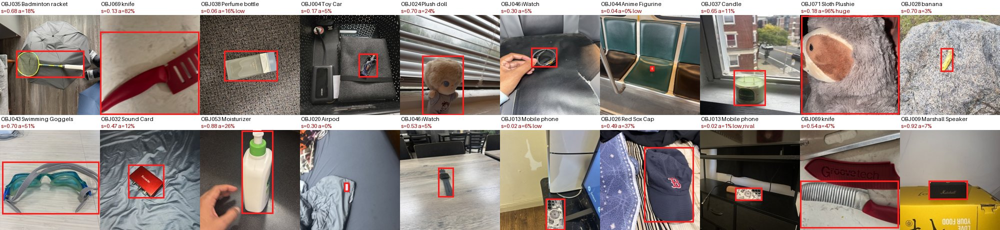

In [12]:
import select_boxes as sb
if not (WORK / "boxes" / "owlv2_candidates.jsonl").exists():
    import extract_boxes                       # ~25 min on a T4; normally shipped in the support zip
    extract_boxes.main()
rows = sb.load()
sb.write_boxes(rows)
sb.counts(rows)
audit = list(csv.DictReader(open(WORK / "review" / "audit_judgments.csv")))
wrong = sum(a["box_ok"] == "False" for a in audit)
used = Counter(r["split"] for r in rows if not r["exclude"])
print(f"audit: {wrong}/{len(audit)} boxes wrong ({wrong / len(audit):.1%})")
print(f"usable photos {sum(used.values()):,} {dict(used)}; excluded {sum(bool(r['exclude']) for r in rows)}")
print("sources:", dict(Counter(r["source"] for r in rows if not r["exclude"])))
import random
from IPython.display import display
from PIL import Image
sample = random.Random(0).sample([r for r in rows if not r["exclude"]], 20)
sb.sheet(sample, OUT / "box_samples.jpg", cols=10, show_rival=False)
display(Image.open(OUT / "box_samples.jpg"))

---
## 4. Generated images

| Set | Built from | Size |
|---|---|---|
| train | Milestone 1 training photos | 3,000 images, class-balanced |
| val | validation photos | each usable photo exactly once |
| test | test photos | each usable photo exactly once |
| stress | test photos only | 40 strict 224 px grids each of 1x2, 1x4, 2x2, 2x3, 3x3 |
| member1-4 | all photos | 100 images each, one seed per group member (record only) |

Layout mix: 50% strict edge-to-edge grids (1x2 to 4x2, 70% at native 224 px), 20% jittered grids,
30% random collages on a mosaic of same-split background photos at native resolution.
Any slot may hold a background-only photo, ~10% of images repeat a class, ~2% have no objects.

6618 object photos with a box; 324 excluded (see boxes/excluded.csv)
train    {'images': 3000, 'objects': 11535, 'classes': 73, 'layouts': {'collage': 881, 'grid': 1522, 'jitter': 597}, 'background_slots': 1750, 'images_with_repeat': 265}  (50s)
val: every photo used; 0 extra uses from repeated-class slots
val      {'images': 268, 'objects': 988, 'classes': 73, 'layouts': {'grid': 142, 'collage': 67, 'jitter': 59}, 'background_slots': 168, 'images_with_repeat': 20}  (53s)
test: every photo used; 0 extra uses from repeated-class slots
test     {'images': 281, 'objects': 1076, 'classes': 73, 'layouts': {'collage': 86, 'jitter': 65, 'grid': 130}, 'background_slots': 204, 'images_with_repeat': 15}  (56s)
stress   {'images': 200, 'objects': 867, 'classes': 73, 'layouts': {'grid': 200}, 'background_slots': 133, 'images_with_repeat': 21}  (58s)
member1  {'images': 100, 'objects': 391, 'classes': 73, 'layouts': {'grid': 50, 'jitter': 21, 'collage': 29}, 'background_slots': 67, 'images_with_rep

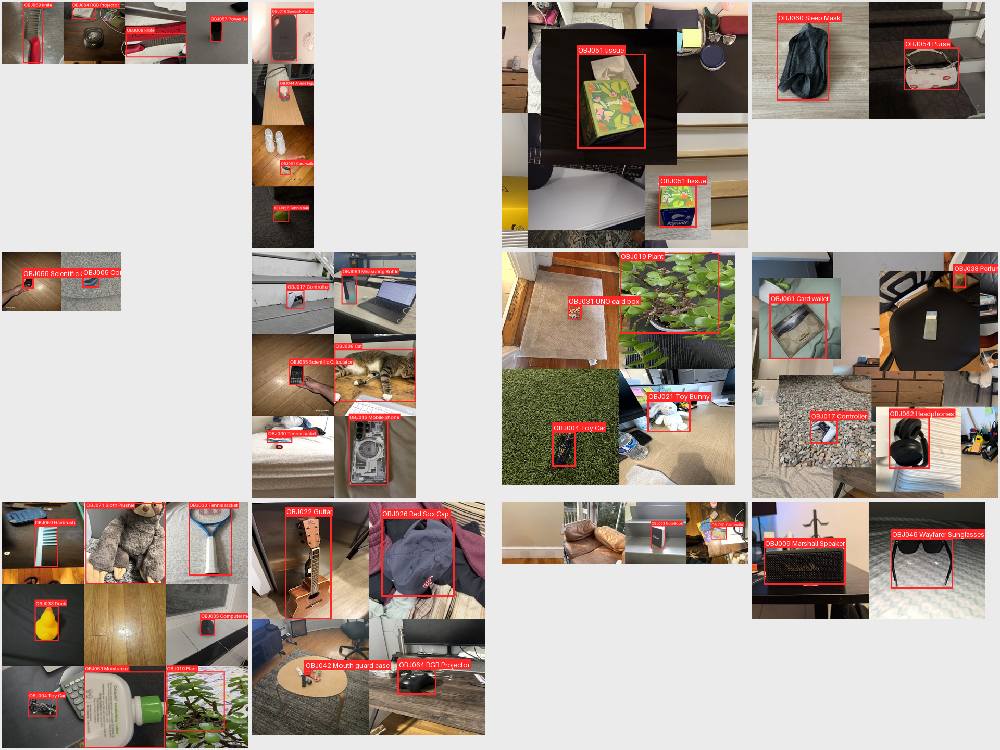

In [13]:
import build_datasets, m2compose, draw
from PIL import Image
DS = WORK / "datasets"
t0 = time.time()
build_datasets.main(DS, small=SMOKE_TEST)
print(f"generated in {time.time() - t0:.0f}s")
MAN = {s: json.load(open(DS / f"manifest_{s}.json")) for s in ("train", "val", "test", "stress")}


def contact(entries, path, cols=4, cell=480):
    S = Image.new("RGB", (cols * cell, ((len(entries) + cols - 1) // cols) * cell), (235, 235, 235))
    for k, (d, e) in enumerate(entries):
        im = draw.draw_labels(DS / d / "images" / e["image"], DS / d / "labels" / e["image"].replace(".jpg", ".txt"),
                              IDS, NAMES, size=13)
        im.thumbnail((cell - 8, cell - 8)); S.paste(im, ((k % cols) * cell + 4, (k // cols) * cell + 4))
    S.save(path, quality=85)
    return S


rng = random.Random(1)
display(contact([("train", e) for e in rng.sample(MAN["train"], 8)] +
                [("stress", e) for e in rng.sample(MAN["stress"], 4)], OUT / "generated_samples.jpg"))

---
## 5. Training

A one-epoch timing run measures the time per epoch on this GPU; the main run then uses a fixed
epoch count that fits the time budget, with early stopping on validation (patience 15).

In [14]:
import pandas as pd
DATA_YAML = DS / "data.yaml"
TRAIN_ARGS = dict(data=str(DATA_YAML), imgsz=IMGSZ, batch=BATCH, seed=SEED, deterministic=True,
                  cache="disk", workers=2, device=DEVICE, project=str(WORK / "runs"), exist_ok=True,
                  plots=True, verbose=False, **AUG)
if SMOKE_TEST:
    EPOCHS, sec_per_epoch = 1, None
else:
    t0 = time.time()
    YOLO(MODEL).train(epochs=1, name="timing", val=True, **TRAIN_ARGS)
    wall = time.time() - t0
    timing = pd.read_csv(WORK / "runs" / "timing" / "results.csv"); timing.columns = [c.strip() for c in timing.columns]
    # per-epoch time logged by Ultralytics (training + validation), without one-off setup costs
    sec_per_epoch = float(timing["time"].iloc[0]) if "time" in timing else wall
    print(f"timing run: {wall:.0f}s wall, {sec_per_epoch:.0f}s for the epoch itself")
    EPOCHS = int(max(10, min(150, TRAIN_MINUTES * 60 // sec_per_epoch)))
train_config = {"model": MODEL, "epochs": EPOCHS, "sec_per_epoch_timing_run": sec_per_epoch,
                "patience": PATIENCE, "imgsz": IMGSZ, "batch": BATCH, "seed": SEED, "augment": AUG,
                "ultralytics": ultralytics.__version__}
(OUT / "train_config.json").write_text(json.dumps(train_config, indent=1))
print(train_config)

New https://pypi.org/project/ultralytics/8.4.175 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.162 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/m2/datasets/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.p

New https://pypi.org/project/ultralytics/8.4.175 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.162 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/m2/datasets/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=42, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.

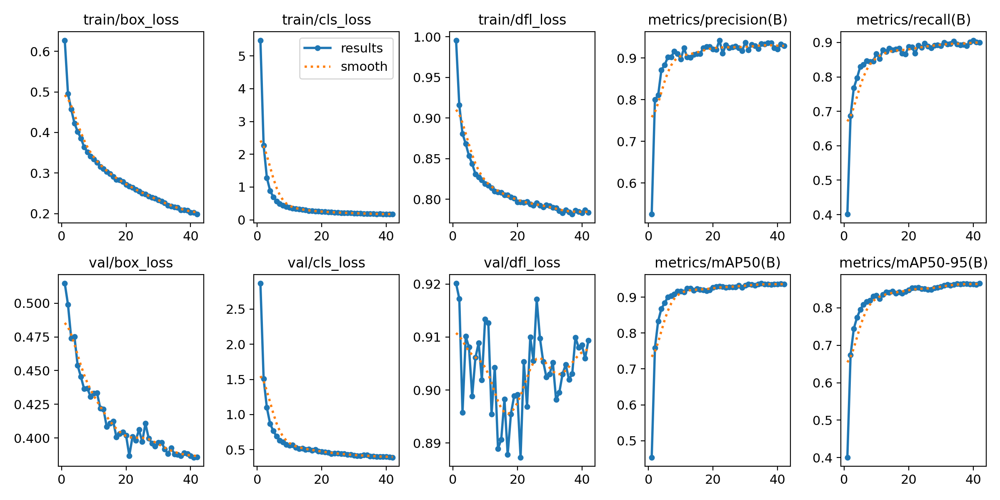

In [15]:
t0 = time.time()
model = YOLO(MODEL)
model.train(epochs=EPOCHS, patience=PATIENCE, name="main", **TRAIN_ARGS)
train_minutes = (time.time() - t0) / 60
RUN = WORK / "runs" / "main"
import pandas as pd
hist = pd.read_csv(RUN / "results.csv"); hist.columns = [c.strip() for c in hist.columns]
best_epoch = int(hist["metrics/mAP50-95(B)"].idxmax()) + 1
print(f"trained {len(hist)} epochs in {train_minutes:.1f} min; best epoch {best_epoch} "
      f"(val mAP50 {hist['metrics/mAP50(B)'].max():.3f}, mAP50-95 {hist['metrics/mAP50-95(B)'].max():.3f})")
best = YOLO(RUN / "weights" / "best.pt")
display(Image.open(RUN / "results.png"))

---
## 6. Test-set detection metrics

Standard detection metrics on the held-out test images (Ultralytics validation on the `test`
split): mAP@0.5, mAP@0.5:0.95, precision, recall, per-class AP and the confusion matrix.

Ultralytics 8.4.162 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,153,835 parameters, 0 gradients, 28.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 44.5±19.0 MB/s, size: 117.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/m2/datasets/test/labels... 281 images, 6 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 281/281 606.0it/s 0.5s
val: New cache created: /content/m2/datasets/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 2.0it/s 9.1s
                   all        281       1076      0.928      0.895      0.931      0.863
Speed: 3.6ms preprocess, 17.1ms inference, 0.0ms loss, 2.5ms postprocess per image
Results saved to /content/m2/runs/test_eval
{'mAP50': 0.9309, 'mAP50_95': 0.863, 'precision': 0.9279, 'rec

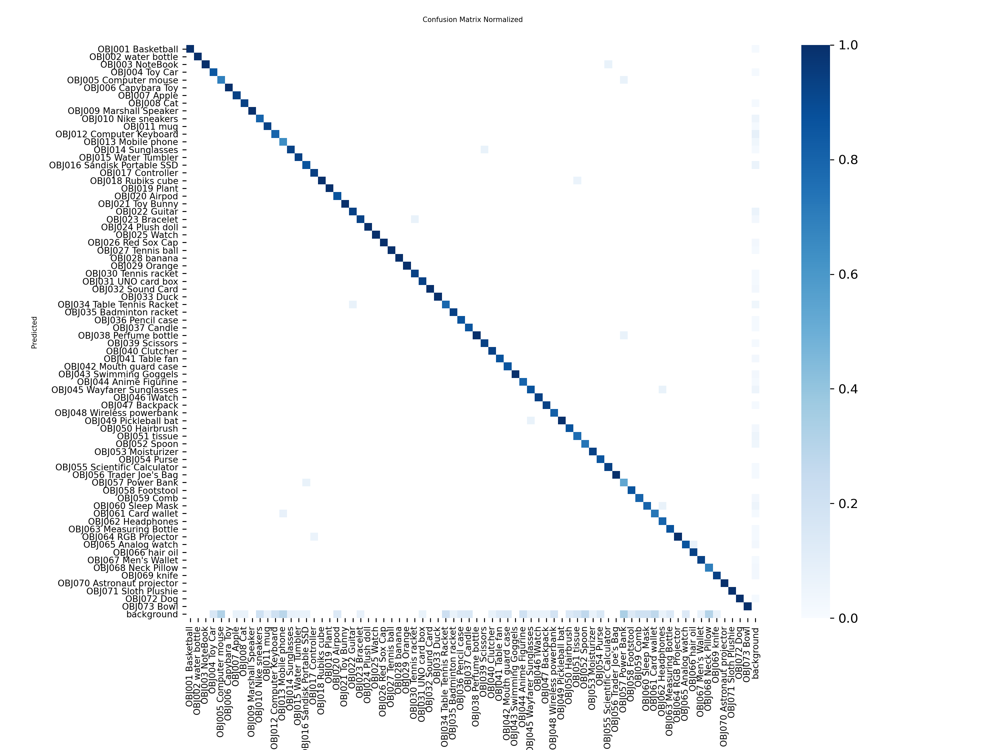

In [16]:
m = best.val(data=str(DATA_YAML), split="test", imgsz=IMGSZ, batch=BATCH, device=DEVICE,
             project=str(WORK / "runs"), name="test_eval", exist_ok=True, plots=True, verbose=False)
test_metrics = {"mAP50": float(m.box.map50), "mAP50_95": float(m.box.map),
                "precision": float(m.box.mp), "recall": float(m.box.mr)}
print({k: round(v, 4) for k, v in test_metrics.items()})
per_class = pd.DataFrame({"class_index": m.box.ap_class_index,
                          "object_id": [IDS[i] for i in m.box.ap_class_index],
                          "object_name": [NAMES[IDS[i]] for i in m.box.ap_class_index],
                          "AP50": m.box.ap50, "AP50_95": m.box.ap})
per_class.to_csv(OUT / "test_per_class_ap.csv", index=False)
print("\nhardest 10 classes (AP50-95):")
print(per_class.sort_values("AP50_95").head(10)[["object_id", "object_name", "AP50", "AP50_95"]].round(3).to_string(index=False))
display(Image.open(WORK / "runs" / "test_eval" / "confusion_matrix_normalized.png"))

---
## 7. Image-level score (requirement 3)

An image counts as correct only if **every object is detected with the correct ID (IoU >= 0.5)
and there are no extra detections**. Predictions use class-agnostic NMS at IoU 0.5 (one label per
object), the same setting as `detect.py`.
The confidence threshold is chosen on the validation images and then applied unchanged to the
test images and the stress suite.

In [17]:
import m2eval


def predict_set(model, split, manifest, chunk=16):
    # A list of paths is run as one batch, so predict in chunks to bound GPU memory.
    preds = {}
    for i in range(0, len(manifest), chunk):
        part = manifest[i:i + chunk]
        paths = [str(DS / split / "images" / e["image"]) for e in part]
        for e, r in zip(part, model.predict(paths, conf=0.01, iou=0.5, agnostic_nms=True, imgsz=IMGSZ,
                                            device=DEVICE, verbose=False, max_det=100)):
            preds[e["image"]] = [{"cls": int(c), "conf": float(s), "box": b}
                                 for b, c, s in zip(r.boxes.xyxy.tolist(), r.boxes.cls.tolist(), r.boxes.conf.tolist())]
    return preds


PRED = {s: predict_set(best, s, MAN[s]) for s in ("val", "test", "stress")}
CONF, sweep = m2eval.choose_threshold(PRED["val"], MAN["val"], CLASS_INDEX)
pd.DataFrame(sweep, columns=["conf", "val_image_accuracy"]).to_csv(OUT / "threshold_sweep_val.csv", index=False)
print(f"threshold chosen on validation: conf >= {CONF:.2f} "
      f"(val image-level accuracy {dict(sweep)[CONF]:.1%})")

layout_key = lambda e: e["layout"] if e["layout"] != "grid" else f"grid {e['rows']}x{e['cols']}"
test_img = m2eval.image_accuracy(PRED["test"], MAN["test"], CLASS_INDEX, CONF, key=lambda e: e["layout"])
stress_img = m2eval.image_accuracy(PRED["stress"], MAN["stress"], CLASS_INDEX, CONF, key=layout_key)
rows_out = [("test", k, *v) for k, v in test_img.items()] + [("stress", k, *v) for k, v in stress_img.items()]
img_level = pd.DataFrame(rows_out, columns=["set", "group", "image_accuracy", "images"])
img_level.to_csv(OUT / "image_level_accuracy.csv", index=False)
print(img_level.round(3).to_string(index=False))
_ = (RUN / "weights" / "detect_config.json").write_text(json.dumps({"conf": CONF, "imgsz": IMGSZ}))

threshold chosen on validation: conf >= 0.25 (val image-level accuracy 65.7%)
   set    group  image_accuracy  images
  test      all           0.609     281
  test  collage           0.709      86
  test   jitter           0.538      65
  test     grid           0.577     130
stress      all           0.625     200
stress grid 1x2           0.850      40
stress grid 1x4           0.725      40
stress grid 2x2           0.600      40
stress grid 2x3           0.500      40
stress grid 3x3           0.450      40


---
## 8. Detector vs the Milestone 1 classifier

Every usable test photo appears in exactly one test image, so the detector can be scored per
photo: correct if a detection overlaps the photo's object box (IoU >= 0.5) with the right ID.
The Milestone 1 DenseNet121 saw the same photos full-frame. Conditions differ (the detector sees
a shrunken photo inside a collage and must also find the object), so this is context, not a
like-for-like comparison.

In [18]:
from scipy.stats import binomtest
pp = m2eval.per_photo(PRED["test"], MAN["test"], CLASS_INDEX, CONF)
det_ok = {}
for x in pp:
    det_ok.setdefault(x["rel"], x["pred"] == x["true"])
cls_rows = {r["rel"]: r for r in csv.DictReader(open(WORK / "boxes" / "m1_densenet121_test_predictions.csv"))}
common = sorted(set(det_ok) & set(cls_rows))
d_ok = np.array([det_ok[k] for k in common]); c_ok = np.array([cls_rows[k]["correct"] == "1" for k in common])
only_d, only_c = int(np.sum(d_ok & ~c_ok)), int(np.sum(~d_ok & c_ok))
p_mc = binomtest(only_d, only_d + only_c, 0.5).pvalue if only_d + only_c else 1.0
missed = sum(1 for x in pp if x["pred"] is None)
comparison = {"photos": len(common), "detector_accuracy": float(d_ok.mean()),
              "densenet121_accuracy": float(c_ok.mean()), "only_detector_right": only_d,
              "only_classifier_right": only_c, "mcnemar_p": float(p_mc), "detector_missed": missed}
pd.DataFrame([{"rel": k, "detector_correct": int(det_ok[k]), "densenet121_correct": int(cls_rows[k]["correct"] == "1")}
              for k in common]).to_csv(OUT / "detector_vs_classifier.csv", index=False)
print(json.dumps({k: round(v, 4) if isinstance(v, float) else v for k, v in comparison.items()}, indent=1))

{
 "photos": 1076,
 "detector_accuracy": 0.9033,
 "densenet121_accuracy": 0.9665,
 "only_detector_right": 16,
 "only_classifier_right": 84,
 "mcnemar_p": 0.0,
 "detector_missed": 90
}


---
## 9. Scene check on background photos

Milestone 1 found the classifier partly recognised each student's scene. Here, any detection
centred on a background-only region (a background tile or a visible piece of the canvas) is a
false detection. Counts are per unique background photo, with how often the false detection
names the photographer's own object (chance is about 1/73).

In [19]:
per_bg, events = m2eval.scene_check(PRED["test"], MAN["test"], CLASS_INDEX, CONF)
scene = pd.DataFrame([{"bg_rel": k, "photographer_object": v["obj"], "times_shown": v["shown"],
                       "false_detections": v["false_dets"], "own_object": v["own_object"]} for k, v in per_bg.items()])
scene.to_csv(OUT / "scene_check_test.csv", index=False)
n_fd = int(scene.false_detections.sum()); n_own = int(scene.own_object.sum())
scene_summary = {"background_photos": len(scene), "background_photos_with_false_detection": int((scene.false_detections > 0).sum()),
                 "false_detections": n_fd, "own_object": n_own,
                 "own_object_rate": n_own / n_fd if n_fd else 0.0, "chance_rate": 1 / len(IDS)}
print(json.dumps({k: round(v, 4) if isinstance(v, float) else v for k, v in scene_summary.items()}, indent=1))

{
 "background_photos": 57,
 "background_photos_with_false_detection": 9,
 "false_detections": 25,
 "own_object": 1,
 "own_object_rate": 0.04,
 "chance_rate": 0.0137
}


---
## 10. Failure gallery

Test images that fail the image-level score. Green: ground truth. Red: detections at the chosen threshold.

110 of 281 test images fail


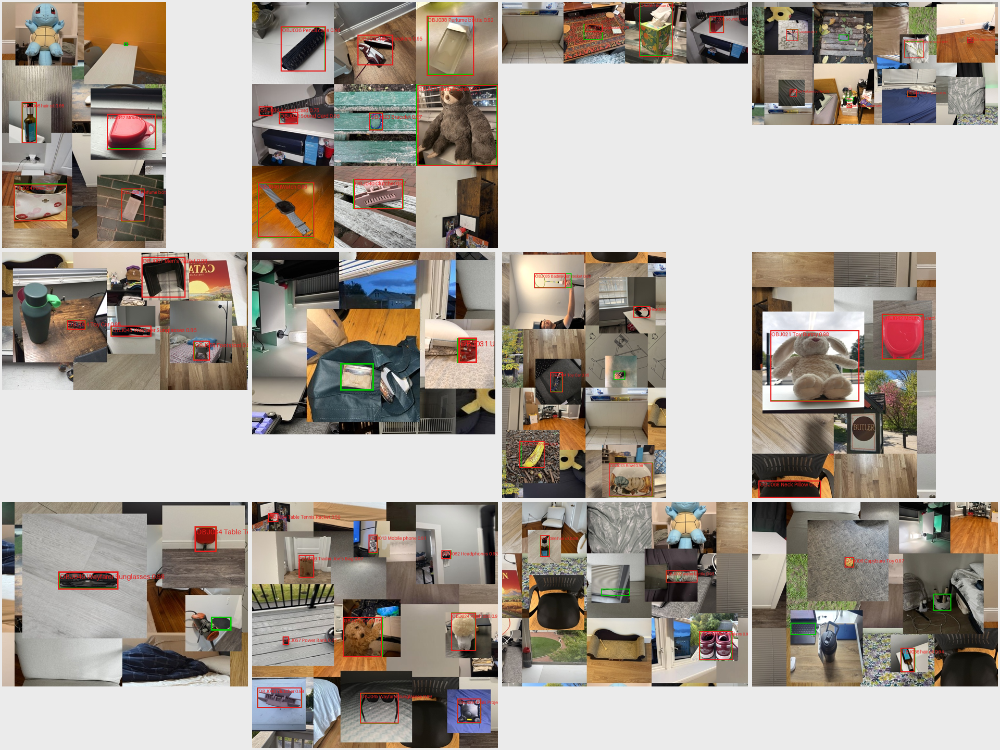

In [20]:
from PIL import ImageDraw
font = draw.font(14)


def show_failure(e):
    im = Image.open(DS / "test" / "images" / e["image"]).convert("RGB"); d = ImageDraw.Draw(im)
    for g in m2eval.gt_objects(e, CLASS_INDEX):
        d.rectangle(g["box"], outline=(0, 200, 0), width=3)
    for p in [p for p in PRED["test"][e["image"]] if p["conf"] >= CONF]:
        d.rectangle(p["box"], outline=(230, 30, 30), width=3)
        d.text((p["box"][0] + 3, p["box"][1] + 2), f"{LABEL(p['cls'])} {p['conf']:.2f}", fill=(230, 30, 30), font=font)
    return im


fails = [e for e in MAN["test"] if not m2eval.image_correct(PRED["test"][e["image"]], m2eval.gt_objects(e, CLASS_INDEX), CONF)]
print(f"{len(fails)} of {len(MAN['test'])} test images fail")
gallery = Image.new("RGB", (4 * 480, 3 * 480), (235, 235, 235))
for k, e in enumerate(random.Random(2).sample(fails, min(12, len(fails)))):
    im = show_failure(e); im.thumbnail((472, 472)); gallery.paste(im, ((k % 4) * 480 + 4, (k // 4) * 480 + 4))
gallery.save(OUT / "failure_gallery.jpg", quality=85); display(gallery)

---
## 11. Inference on any image

`detect.py` is a standalone script that runs on a laptop (offline, MPS or CPU). It accepts
any size, aspect ratio and format, applies EXIF orientation, prints every detection (Object ID,
name, confidence, box in pixels) in reading order and saves an annotated image.

In [21]:
%%writefile detect.py
"""Detect the 73 class objects in any image and save an annotated copy.

    python detect.py IMAGE [IMAGE ...] [--weights best.pt] [--conf 0.5] [--out annotated/]

Runs offline (no network calls): the model is loaded from a local weights file
and annotations are drawn with PIL using a system font. The confidence
threshold defaults to the one chosen on the validation set, read from
detect_config.json next to the weights file when present.
Accepts jpg/jpeg/png (including RGBA) of any size; EXIF orientation is applied.
"""
import argparse
import json
import os
import sys
from pathlib import Path

os.environ.setdefault("YOLO_OFFLINE", "1")
os.environ.setdefault("YOLO_AUTOINSTALL", "false")   # never pip-install anything at inference time

from PIL import Image, ImageDraw, ImageFont, ImageOps  # noqa: E402

FONT_PATHS = ["/System/Library/Fonts/Supplemental/Arial Bold.ttf", "/System/Library/Fonts/Helvetica.ttc",
              "/Library/Fonts/Arial Bold.ttf", "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf",
              "C:/Windows/Fonts/arialbd.ttf"]
NMS_IOU = 0.5        # one box per object: overlapping boxes of any class are merged
PALETTE = [(230, 25, 75), (60, 180, 75), (0, 130, 200), (245, 130, 48), (145, 30, 180),
           (70, 140, 140), (240, 50, 230), (128, 128, 0), (0, 0, 128), (170, 110, 40)]


def load_font(size):
    for f in FONT_PATHS:
        if Path(f).exists():
            return ImageFont.truetype(f, size)
    return ImageFont.load_default(size)


def open_image(path):
    """RGB PIL image with EXIF orientation applied; transparency composited on white."""
    im = ImageOps.exif_transpose(Image.open(path))
    if im.mode in ("RGBA", "LA", "P"):
        im = im.convert("RGBA")
        bg = Image.new("RGBA", im.size, (255, 255, 255, 255))
        im = Image.alpha_composite(bg, im)
    return im.convert("RGB")


def reading_order(dets):
    """Sort detections left to right within rows, rows top to bottom."""
    if not dets:
        return dets
    hs = sorted(d["box"][3] - d["box"][1] for d in dets)
    tol = 0.5 * hs[len(hs) // 2]
    rows, current = [], []
    for d in sorted(dets, key=lambda d: (d["box"][1] + d["box"][3]) / 2):
        cy = (d["box"][1] + d["box"][3]) / 2
        if current and cy - current[0]["_cy"] > tol:
            rows.append(current); current = []
        d["_cy"] = cy
        current.append(d)
    rows.append(current)
    out = []
    for row in rows:
        out += sorted(row, key=lambda d: d["box"][0])
    for d in out:
        d.pop("_cy", None)
    return out


class Detector:
    def __init__(self, weights, conf=None, device=None):
        from ultralytics import YOLO
        import torch
        self.model = YOLO(str(weights))
        cfg = Path(weights).with_name("detect_config.json")
        saved = json.loads(cfg.read_text()) if cfg.exists() else {}
        self.conf = conf if conf is not None else saved.get("conf", 0.5)
        self.imgsz = saved.get("imgsz", 640)
        self.device = device if device is not None else ("mps" if torch.backends.mps.is_available() else "cpu")
        self.names = self.model.names                         # {index: "OBJ018 Rubiks cube"}

    def __call__(self, path):
        im = open_image(path)
        r = self.model.predict(im, conf=self.conf, iou=NMS_IOU, imgsz=self.imgsz, agnostic_nms=True,
                               device=self.device, verbose=False)[0]
        dets = []
        for (x0, y0, x1, y1), c, s in zip(r.boxes.xyxy.tolist(), r.boxes.cls.tolist(), r.boxes.conf.tolist()):
            label = self.names[int(c)]
            oid, _, name = label.partition(" ")
            dets.append({"object_id": oid, "name": name, "confidence": round(float(s), 3),
                         "box": [round(x0), round(y0), round(x1), round(y1)]})
        return im, reading_order(dets)


def annotate(im, dets):
    im = im.copy()
    d = ImageDraw.Draw(im)
    size = max(18, round(min(im.size) / 22))
    font = load_font(size)
    width = max(3, size // 6)
    for k, det in enumerate(dets):
        col = PALETTE[int(det["object_id"][3:]) % len(PALETTE)]
        x0, y0, x1, y1 = det["box"]
        d.rectangle([x0, y0, x1, y1], outline=col, width=width)
        text = f"{det['object_id']} {det['name']} {det['confidence']:.2f}"
        tw, th = d.textbbox((0, 0), text, font=font)[2:]
        ty = y0 - th - 8 if y0 - th - 8 >= 0 else y0
        tx = min(max(0, x0), max(0, im.width - tw - 8))
        d.rectangle([tx, ty, tx + tw + 8, ty + th + 8], fill=col)
        d.text((tx + 4, ty + 3), text, fill="white", font=font)
    return im


def main(argv=None):
    ap = argparse.ArgumentParser(description=__doc__.split("\n")[0])
    ap.add_argument("images", nargs="+")
    ap.add_argument("--weights", default=str(Path(__file__).with_name("best.pt")))
    ap.add_argument("--conf", type=float, default=None)
    ap.add_argument("--device", default=None)
    ap.add_argument("--out", default="annotated")
    a = ap.parse_args(argv)
    det = Detector(a.weights, a.conf, a.device)
    out = Path(a.out); out.mkdir(parents=True, exist_ok=True)
    for p in a.images:
        if not Path(p).is_file():
            print(f"\n{p}: file not found")
            continue
        try:
            im, dets = det(p)
        except Exception as e:                      # unreadable or unsupported image
            print(f"\n{p}: cannot read image ({e.__class__.__name__}: {e})")
            continue
        print(f"\n{p}  ({im.width}x{im.height}, conf >= {det.conf:.2f}): {len(dets)} object(s)")
        for i, x in enumerate(dets, 1):
            print(f"  {i:>2}. {x['object_id']} {x['name']:<24} {x['confidence']:.2f}   box {x['box']}")
        dst = out / (Path(p).stem + "_annotated.jpg")
        annotate(im, dets).save(dst, quality=92)
        print(f"  saved {dst}")
    return 0


if __name__ == "__main__":
    sys.exit(main())

Writing detect.py



stress_1x2_00000.jpg (448x224): 2 object(s)
  1. OBJ014 Sunglasses               0.89  box [97, 66, 130, 117]
  2. OBJ014 Sunglasses               0.90  box [315, 87, 375, 142]


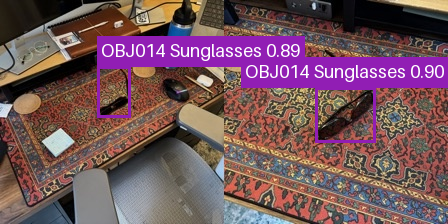


stress_2x2_00020.jpg (448x448): 0 object(s)


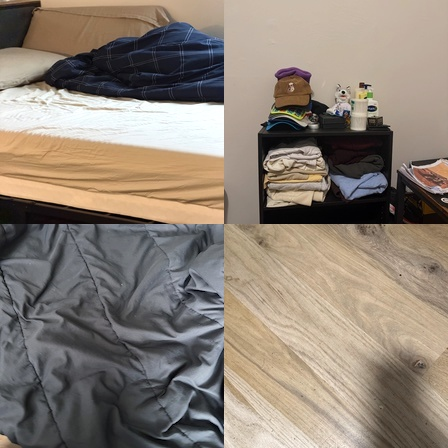


stress_3x3_00039.jpg (672x672): 7 object(s)
  1. OBJ038 Perfume bottle           0.96  box [75, 85, 117, 182]
  2. OBJ045 Wayfarer Sunglasses      0.94  box [303, 97, 382, 123]
  3. OBJ012 Computer Keyboard        0.50  box [118, 292, 160, 374]
  4. OBJ030 Tennis racket            0.98  box [509, 226, 619, 442]
  5. OBJ043 Swimming Goggels         0.97  box [9, 509, 211, 632]
  6. OBJ068 Neck Pillow              0.98  box [246, 453, 447, 670]
  7. OBJ002 water bottle             0.97  box [503, 455, 584, 644]


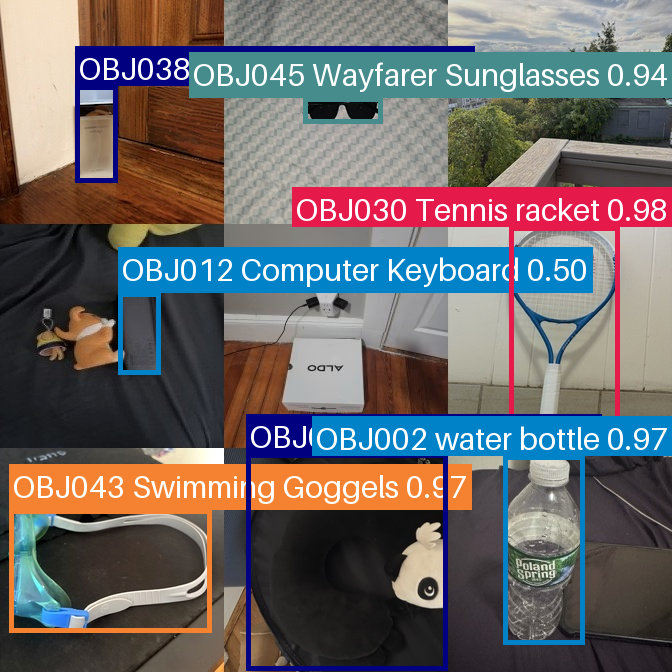


test_00000.jpg (761x428): 3 object(s)
  1. OBJ060 Sleep Mask               0.99  box [25, 21, 251, 247]
  2. OBJ012 Computer Keyboard        0.94  box [645, 148, 761, 189]
  3. OBJ028 banana                   0.97  box [170, 265, 303, 373]


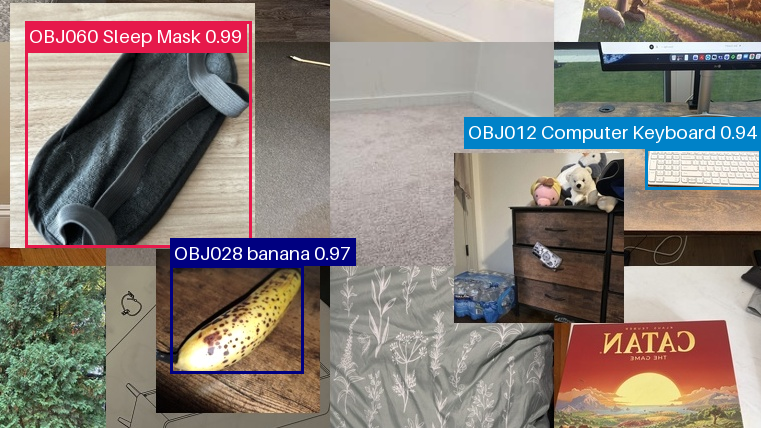

In [22]:
import detect
importlib.reload(detect)
detector = detect.Detector(RUN / "weights" / "best.pt", device=DEVICE)
examples = [DS / "stress" / "images" / MAN["stress"][i]["image"] for i in (0, len(MAN["stress"]) // 2, -1)]
examples += [DS / "test" / "images" / MAN["test"][0]["image"]]
for p in examples:
    im, dets = detector(p)
    print(f"\n{p.name} ({im.width}x{im.height}): {len(dets)} object(s)")
    for i, x in enumerate(dets, 1):
        print(f"  {i}. {x['object_id']} {x['name']:<24} {x['confidence']:.2f}  box {x['box']}")
    a = detect.annotate(im, dets); a.save(OUT / f"inference_{p.stem}.jpg", quality=90)
    a.thumbnail((900, 900)); display(a)

---
## 12. Save outputs

In [24]:
demo = OUT / "demo"; demo.mkdir(exist_ok=True)
shutil.copy(RUN / "weights" / "best.pt", demo / "best.pt")
shutil.copy(RUN / "weights" / "detect_config.json", demo / "detect_config.json")
shutil.copy(WORK / "detect.py", demo / "detect.py")
if RETRAIN_ALL_PHOTOS:
    shutil.copy(WORK / "runs" / "all_photos" / "weights" / "demo.pt", demo / "demo_all_photos.pt")
for f in ("data.yaml", "classes.csv", "summary.json") + tuple(f"manifest_{s}.json" for s in ("train", "val", "test", "stress")):
    shutil.copy(DS / f, OUT / f)
for f in ("boxes.csv", "excluded.csv", "flag_counts.csv"):
    shutil.copy(WORK / "boxes" / f, OUT / f)
shutil.copytree(DS / "members", OUT / "member_sets", dirs_exist_ok=True)
for d in ("main", "test_eval"):
    shutil.copytree(WORK / "runs" / d, OUT / "runs" / d, dirs_exist_ok=True)
assert_safe_write(OUTPUT_ZIP)
with zipfile.ZipFile(OUTPUT_ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob("*"):
        if p.is_file():
            z.write(p, p.relative_to(OUT))
print(f"saved {OUTPUT_ZIP} ({OUTPUT_ZIP.stat().st_size / 1e6:.0f} MB)")

saved /content/drive/MyDrive/IE7615_Milestone2_outputs_960.zip (119 MB)


---
## 13. Summary of findings

In [25]:
s_layouts = {k: v[0] for k, v in stress_img.items() if k != "all"}
summary = {
    "data": {"usable_photos": int(sum(used.values())), "box_audit_error_rate": wrong / len(audit),
             "train_images": len(MAN["train"]), "val_images": len(MAN["val"]), "test_images": len(MAN["test"]),
             "stress_images": len(MAN["stress"])},
    "training": {"epochs_planned": EPOCHS, "epochs_run": len(hist), "best_epoch": best_epoch,
                 "minutes": round(train_minutes, 1)},
    "test_detection": {k: round(v, 4) for k, v in test_metrics.items()},
    "confidence_threshold_from_val": CONF,
    "image_level_accuracy": {"test": round(test_img["all"][0], 4), "stress": round(stress_img["all"][0], 4),
                             "stress_by_layout": {k: round(v, 4) for k, v in s_layouts.items()}},
    "detector_vs_classifier": {k: round(v, 4) if isinstance(v, float) else v for k, v in comparison.items()},
    "scene_check": {k: round(v, 4) if isinstance(v, float) else v for k, v in scene_summary.items()},
}
(OUT / "summary_of_findings.json").write_text(json.dumps(summary, indent=1))
print(json.dumps(summary, indent=1))

{
 "data": {
  "usable_photos": 6618,
  "box_audit_error_rate": 0.07534246575342465,
  "train_images": 3000,
  "val_images": 268,
  "test_images": 281,
  "stress_images": 200
 },
 "training": {
  "epochs_planned": 42,
  "epochs_run": 42,
  "best_epoch": 42,
  "minutes": 68.5
 },
 "test_detection": {
  "mAP50": 0.9309,
  "mAP50_95": 0.863,
  "precision": 0.9279,
  "recall": 0.8952
 },
 "confidence_threshold_from_val": 0.25,
 "image_level_accuracy": {
  "test": 0.6085,
  "stress": 0.625,
  "stress_by_layout": {
   "grid 1x2": 0.85,
   "grid 1x4": 0.725,
   "grid 2x2": 0.6,
   "grid 2x3": 0.5,
   "grid 3x3": 0.45
  }
 },
 "detector_vs_classifier": {
  "photos": 1076,
  "detector_accuracy": 0.9033,
  "densenet121_accuracy": 0.9665,
  "only_detector_right": 16,
  "only_classifier_right": 84,
  "mcnemar_p": 0.0,
  "detector_missed": 90
 },
 "scene_check": {
  "background_photos": 57,
  "background_photos_with_false_detection": 9,
  "false_detections": 25,
  "own_object": 1,
  "own_object_rat